# Choosing an engine and an enhancement, and seeing what it does to a size distribution

Two decisions sit in front of every run, and both are opt-in:

1. **Which UIOOPS engine.** v3.5 is the default (`uiops.engine()`).
2. **Which enhancements.** The port (`arrayprobe run`) never applies one -- it is the faithful
   reproduction and nothing else. Corrections live in the separate `arrayprobe-enhancements`
   package and are applied by `arrayprobe-enhanced run`, chosen in the config file's
   `[enhancements]` table.

This notebook takes one enhancement, `outoffocus` (the Korolev 2007 out-of-focus
size correction that `sizeDist.m:793` computes and never applies), runs it A/B on the tracked
dense demo flight under the v3.5 engine, and puts the size distributions side by side --
the A/B-consequence table every enhancement is required to carry
(`enhancements_uiops/docs/CORRECTIONS.md`).

**This is an A/B on synthetic data, not validation.** `tests/data/demo_flight_dense_raw.2DS`
is a hand-built 20-second 2D-S file of 240 particles, rings and bars among them
(`tests/data/demo_flight_dense_digest.json`). It shows what
the correction *does*; how large the effect is on real cloud is a campaign measurement
not made in this notebook. Needs the enhancements package installed
(`pip install -e enhancements_uiops`), no campaign data, no MATLAB/Octave.

**Before this:** [08_opt_ins](08_opt_ins.ipynb) (Every opt-in, and how to turn it on). **Next:** [10_labelling_particles](10_labelling_particles.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. The engine choice

`uiops.engine()` dispatches and computes nothing; it names which port a run goes through.
In a config file the same choice is `[run] engine = "3.5"`, the default, and
`[fidelity] profile` picks the thresholds (`stock-v3.5`, ...).

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/2_processing/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import uiops

ENGINES = ("3.5",)

print("versions implemented:", uiops.VERSIONS)
print("default engine:      ", uiops.engine())

versions implemented: ('3.5',)
default engine:       Engine(version='3.5')


## 2. What can be switched on, and where

Every enhancement is registered with a stage and an on/off default for `arrayprobe-enhanced run`.
**To turn one on or off, name it in the config file's `[enhancements]` table** -- e.g.

```toml
[enhancements]
outoffocus = true
hole_edge_swap = false
```

then run `arrayprobe-enhanced run my_run.toml base*.2DS`. An unknown key is an error, not an
ignored line, and switching on one that the chosen engine does not need (because v3.5 already
fixed the defect) raises `NotApplicableToEngine` before anything is written -- the
double-correction guard. The table below is read from the registry, not typed.

In [3]:
from arrayprobe_enhancements import applicability, pipeline, registry

print(f"{'enhancement':28s} {'stage':8s} {'default':8s} {'wired':6s} {'v3.5':5s}")
for name, spec in sorted(registry.REGISTRY.items()):
    wired = "yes" if name in pipeline._APPLIERS else "-"
    on = "yes" if applicability.applicable(name, "3.5") else "-"
    print(f"{name:28s} {spec.stage:8s} {'on' if spec.default_on else 'off':8s} {wired:6s} "
          f"{on:5s}")
print(f"\n{len(registry.REGISTRY)} registered; 'wired' = applied by `arrayprobe-enhanced run` today.")

enhancement                  stage    default  wired  v3.5 
analysis                     sd       off      -      yes  
arco_export                  product  off      yes    yes  
arm_export                   product  off      yes    yes  
brown_francis_1995           none     off      -      yes  
cf_export                    product  off      yes    yes  
conc_arear_fix               sd       off      -      -    
diode_range_fix              proc     off      -      -    
distance_rejection           sd       off      -      yes  
dmax_sensitivity             proc     off      -      yes  
effective_density            proc     off      -      yes  
field2006_shatter            sd       off      yes    yes  
hole_edge_swap               proc     off      yes    yes  
int16_double_fix             sd       off      -      -    
int_arr_rollback_fix         proc     off      yes    yes  
intarr_policy                sd       off      -      yes  
intarr_threshold_fix         sd       of

This cell shows how a configuration table becomes a decision for every registered enhancement: the names listed are switched on or off as written, and every other name takes its default for the chosen engine.

In [4]:
# What a config file's table resolves to -- every registered name gets a decision.
resolved = registry.resolve({"outoffocus": True, "hole_edge_swap": False}, engine="3.5")
print("outoffocus    ->", resolved["outoffocus"])
print("hole_edge_swap ->", resolved["hole_edge_swap"])
print("names ON under this table:", sum(resolved.values()), "of", len(resolved))

outoffocus    -> True
hole_edge_swap -> False
names ON under this table: 1 of 42


## 3. Run the dense demo flight through each engine

`run_flight.py`'s own stage functions, the same ones `arrayprobe run` drives. The v3.5 engine
takes its true airspeed from an aircraft file, so a small one is written that brackets the demo's
06:06:40-06:06:59 window (the same shape `tests/test_run_from_config_v35.py` established).

In [5]:
import shutil
import sys
import tempfile
from pathlib import Path

import netCDF4   # writes the aircraft file and hands raw handles to the enhancement
import numpy as np
import xarray as xr   # reads the output files; an example-only dependency, see examples/README.md

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402

from arrayprobe.profiles import STOCK_V35  # noqa: E402

run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints
DENSE_RAW = Path("tests/data/demo_flight_dense_raw.2DS")
tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)


def write_aircraft(path, first_s=6 * 3600 + 6 * 60 + 20, n=50, tas_mps=130.0):
    secs = first_s + np.arange(n)
    hhmmss = (secs // 3600) * 10000 + (secs % 3600 // 60) * 100 + secs % 60
    with netCDF4.Dataset(str(path), "w", format="NETCDF3_CLASSIC") as ds:
        ds.createDimension("time", n)
        ds.createVariable("Time", "f8", ("time",))[:] = hhmmss.astype(float)
        ds.createVariable("TAS", "f8", ("time",))[:] = np.full(n, tas_mps)
    return path


MODULE_DEFAULTS = (run_flight.ENGINE, run_flight.PROFILE, run_flight.TAS_FILE)
DEFAULTS = {}
runs = {}
for engine in ENGINES:
    out = root / f"engine_{engine}"
    out.mkdir()
    raw = out / "base160101000000.2DS"
    shutil.copyfile(DENSE_RAW, raw)
    if engine == "3.5":  # module globals are what `--engine` / `[run] engine` set
        run_flight.ENGINE, run_flight.PROFILE = "3.5", STOCK_V35
        run_flight.TAS_FILE = str(write_aircraft(out / "aircraft.cdf"))
        DEFAULTS["3.5"] = (run_flight.ENGINE, run_flight.PROFILE, run_flight.TAS_FILE)
    image = run_flight.stage2(raw, out)
    proc = run_flight.stage3(image, out)
    runs[engine] = {"out": out, "raw": raw, "image": image, "proc": proc}
    print(f"engine {engine:5s} ({getattr(run_flight.PROFILE, 'name', run_flight.PROFILE)}): "
          f"{image.name}, {proc.name}")

engine 3.5   (stock-v3.5): base160101000000.H.nc, proc.base160101000000.H.nc


## 4. Apply `outoffocus` to the proc file

An optical array probe photographs each particle as it crosses a laser beam. A droplet that
passes far from the focal plane casts a blurred shadow: it looks like a ring with a bright
centre ("hollow") and appears larger than it is. Korolev (2007) relates the size of the
bright spot to how far the particle was from focus, which gives a depth `part_z` and a
`size_factor`, and the true diameter is $D_0 = D_m / \mathrm{size\_factor}$, where $D_m$ is
the measured diameter.

`apply_outoffocus` re-runs the engine's own reject stage on each particle's reconstructed
image with the hollow test switched on, recomputes `part_z` and `size_factor`, and returns the
corrected diameters. A particle the engine already marked hollow (reject code `'H'`) and
corrected itself is left as written, so nothing is divided twice. **The accept/reject
decision is untouched**: only diameters can move. The next cell applies it to the proc file
section 3 wrote; it reads the files and writes nothing. The files are opened with `netCDF4`
rather than xarray because the correction works on the raw on-disk variables, unscaled.


In [7]:
# Section 4 on the default engine: the correction, particle by particle.
from arrayprobe_enhancements.outoffocus import apply_outoffocus
from arrayprobe_uiops.measure import STOCK_V35_REJECT_CONFIG

run35 = runs["3.5"]
with netCDF4.Dataset(run35["image"]) as img, netCDF4.Dataset(run35["proc"]) as proc_ds:
    diam_a = np.asarray(proc_ds.variables["image_diam_minR"][:], float)
    v = proc_ds.variables["image_diam_minR"]
    diam_units = next((v.getncattr(n) for n in v.ncattrs() if n.lower() == "units"), "not stated")
    oof = apply_outoffocus(img, proc_ds, config=STOCK_V35_REJECT_CONFIG, engine="3.5")
diam_b = np.asarray(oof.corrected_diam, float)
# Exact comparison; a missing value on both sides is not a change.
moved = ~np.isclose(diam_b, diam_a, rtol=0, atol=0, equal_nan=True)
with xr.open_dataset(run35["proc"], mask_and_scale=False, decode_times=False) as proc_ds:
    reject = np.asarray(proc_ds["image_auto_reject"][:]).astype(int)
has_depth = np.asarray(oof.part_z) > 0

print(f"particles in the proc file:               {diam_a.size}")
print(f"units of image_diam_minR in the file:     {diam_units}")
print(f"with a depth estimate (part_z > 0):       {int(has_depth.sum())}")
print(f"  of those, already marked hollow ('H'):  {int((reject[has_depth] == ord('H')).sum())}")
print(f"diameters the correction changes:         {int(moved.sum())}")
if moved.any():
    print(f"median size_factor among them (unitless): {np.median(np.asarray(oof.size_factor)[moved]):.3f}")
    print(f"median diameter change among them ({diam_units}): "
          f"{np.median(diam_b[moved] - diam_a[moved]):+.4f}")


particles in the proc file:               240
units of image_diam_minR in the file:     mm
with a depth estimate (part_z > 0):       40
  of those, already marked hollow ('H'):  40
diameters the correction changes:         0


Read the printed lines as the whole per-particle result. A particle needs a depth estimate
before it can be corrected, and a particle the engine already corrected is left alone, so the
number of changed diameters can be much smaller than the number with a depth estimate -- on
this demo flight it can be zero. That is why every enhancement is judged by an A/B on the
size distribution rather than by how many particles it touches.

## 5. The size-distribution consequence

Run A is the proc file as the engine wrote it; run B is a copy with the corrected diameters
written into `image_diam_minR`. Each goes into its own folder with the proc file's `.call`
provenance stamp and the true-airspeed sidecar, so the size-distribution stage accepts it, and
that stage then runs **unmodified** over both. The diameters are written into the copy with
`netCDF4`, which edits the raw on-disk variable in place. The next cell compares the two outputs bin by
bin.


In [8]:
def size_distribution(proc, folder, diam=None):
    """Copy the proc file (and what the stage checks) into `folder`, optionally
    replace its diameters, and run the size-distribution stage there."""
    folder.mkdir()
    copy = folder / proc.name
    shutil.copyfile(proc, copy)
    shutil.copyfile(f"{proc}.call", f"{copy}.call")
    shutil.copyfile(proc.parent / "base160101000000.tas.csv", folder / "base160101000000.tas.csv")
    if diam is not None:
        with netCDF4.Dataset(copy, "r+") as ds:
            ds.variables["image_diam_minR"][:] = diam
    return run_flight.stage4(copy, "base160101000000", folder)


def binned_counts(sd):
    with xr.open_dataset(sd, mask_and_scale=False, decode_times=False) as ds:
        c = np.nan_to_num(np.asarray(ds["count"][:], float))
        mid = np.asarray(ds["bin_mid"][:], float)
    c = c if c.shape[0] == mid.size else c.T  # (bin, time)
    return mid, c.sum(axis=1)


run_flight.ENGINE, run_flight.PROFILE, run_flight.TAS_FILE = DEFAULTS["3.5"]
sd_a = size_distribution(run35["proc"], run35["out"] / "ab_A")
sd_b = size_distribution(run35["proc"], run35["out"] / "ab_B", diam=diam_b)
bin_mid, count_a = binned_counts(sd_a)
_, count_b = binned_counts(sd_b)

print(f"size bins:                          {bin_mid.size}")
print(f"particles counted, A (as written):  {count_a.sum():.0f}")
print(f"particles counted, B (corrected):   {count_b.sum():.0f}")
print(f"bins whose count changes:           {int((count_a != count_b).sum())}")


size bins:                          128
particles counted, A (as written):  228
particles counted, B (corrected):   228
bins whose count changes:           0


This cell plots the size distribution, A as the engine writes it and B with the correction
applied, against each bin's mid-point diameter. Where the two lines coincide, the correction
moved no particle out of its size bin.


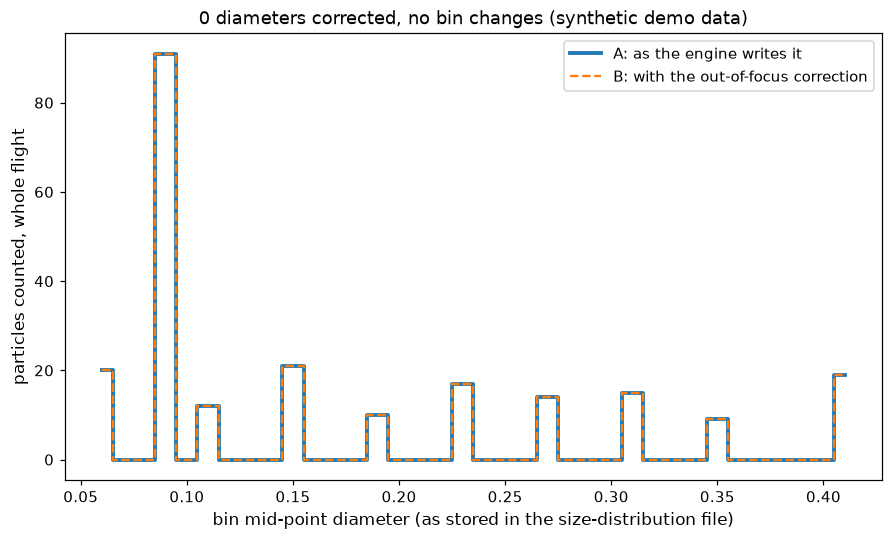

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11})
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
used = np.nonzero((count_a > 0) | (count_b > 0))[0]
lo, hi = (int(used[0]), int(used[-1]) + 1) if used.size else (0, bin_mid.size)
ax.step(bin_mid[lo:hi], count_a[lo:hi], where="mid", linewidth=2.5, color="tab:blue",
        label="A: as the engine writes it")
ax.step(bin_mid[lo:hi], count_b[lo:hi], where="mid", linewidth=1.5, linestyle="--",
        color="tab:orange", label="B: with the out-of-focus correction")
ax.set_xlabel("bin mid-point diameter (as stored in the size-distribution file)")
ax.set_ylabel("particles counted, whole flight")
n_changed = int((count_a != count_b).sum())
ax.set_title(f"{int(moved.sum())} diameters corrected, "
             + ("no bin changes" if n_changed == 0 else f"{n_changed} bins change")
             + " (synthetic demo data)", fontsize=12)
ax.legend(fontsize=10)
plt.show()


*Figure 1. Particles counted in each size bin of the size-distribution file for the whole demo flight, as the engine writes it (A, solid) and with the out-of-focus correction applied (B, dashed, drawn on top). Where the correction moves no particle across a bin edge the two lines coincide; bins empty in both runs at either end are not drawn.*


## 6. The same thing in one command

What sections 3-5 did by hand is what `arrayprobe-enhanced run` does for every enhancement a
configuration file switches on: it runs the engine first, then writes each correction into a
copy of the proc file (`<stem>.enh.proc.nc`), with a provenance sidecar naming what was
applied, what was skipped and why. **A name the `[enhancements]` table does not mention is
off**, so only `outoffocus` is applied below. To read the size-distribution consequence, run
the size-distribution stage on that copy, as section 5 did. The next cell writes a small
configuration file and calls the same entry point from Python.


In [14]:
cfg_dir = root / "one_command_default_engine"
cfg_dir.mkdir()
shutil.copyfile(DENSE_RAW, cfg_dir / "base160101000000.2DS")
write_aircraft(cfg_dir / "aircraft.cdf")
(cfg_dir / "run.toml").write_text(
    '[fidelity]\nprofile = "stock-v3.5"\n'
    '[run]\nengine = "3.5"\npreset = "DEMO_2DS_H"\nout = "_decoded"\nstages = "234"\n'
    'tas_file = "aircraft.cdf"\n'
    '[enhancements]\noutoffocus = true\n', encoding="utf-8")
report = pipeline.apply_enhancements(cfg_dir / "run.toml", [cfg_dir / "base160101000000.2DS"])[0]
print("applied:", report["applied"])
print("skipped:", len(report["skipped"]), "(each with its reason in the sidecar)")
print("written:", sorted(p.name for p in (cfg_dir / "_decoded").glob("*.enh.*")))


enhancements: 1 of 42 ON for engine 3.5 (from <tmp>\one_command_default_engine\run.toml)
  ON   outoffocus                     (applies)
  OFF  41 not named true in [enhancements] (or not applicable to engine 3.5)
applied: ['outoffocus']
skipped: 0 (each with its reason in the sidecar)
written: ['base160101000000.enh.proc.nc', 'base160101000000.enh.proc.nc.call', 'base160101000000.enh.proc.nc.enhancements.json', 'base160101000000.enh.sd.nc', 'base160101000000.enh.sd.nc.call', 'base160101000000.enh.sd.nc.enhancements.json', 'base160101000000.enh.sd.nc.tasqc.json']


## Where to go next

- `enhancements_uiops/docs/CORRECTIONS.md` -- every enhancement's equivalence and A/B proof, one part
  per module.
- `enhancements_uiops/tools/outoffocus_ab.py` -- this A/B as a script, for a real decoded flight.
- `docs/developer/TWO_ENGINES.md` -- which engine to pick, and why "default" and
  "authoritative" are two different engines here.
- `docs/06-configuration.md` -- the whole config file, `[enhancements]` included.